# Competing Platforms in Mobile Crowdsensing: D1 simulation

Abdullah Sajid, Mishal Sagar (LUMS, EE567/CS6315 Multiagent Systems)

Two apps (P1 = air quality, P2 = traffic) post bounties on city blocks. Each hour, 50 people choose **one task** (an app and a block) or skip the hour. The notebook runs three experiments:

| # | Experiment | Question |
|-|-|-|
| 1 | **Baseline:** fixed prices | What coverage and profits do we get with no learning at all? |
| 2 | **Learning prices:** Q-learning platforms | Do the apps learn to keep pay low ("tacit collusion") without communicating? |
| 3 | **Lying users:** rival-offer learning with 0/25/50% liars | Who gains and who loses when users inflate what the rival paid them? |

Sections 0 and 1 check the equilibrium results that the experiments rely on.
The full mathematical formulation follows; it is also in `formulation.md`.

**Running in Google Colab:** run the next cell first. It clones the repository, which holds the code, the processed Beijing week and cached results, and installs Mesa. This pilot notebook takes about 10 minutes.

In [ ]:
# --- Colab setup (skipped when running locally) ---
import os, sys
if "google.colab" in sys.modules and not os.path.exists("crowdsim"):
    if not os.path.exists("competing-platforms-crowdsensing"):
        !git clone -q https://github.com/abdullahsajidfr/competing-platforms-crowdsensing.git
    %cd competing-platforms-crowdsensing
    !pip -q install "mesa>=3.1"


# Mathematical formulation

**Competing Platforms in Mobile Crowdsensing: Learning Platforms and Strategic Users**

## 1. Environment

| Symbol | Meaning | D1 value |
|-|-|-|
| $\mathcal G$ | city blocks (500 m cells) | $10\times10$, $|\mathcal G|=100$ |
| $\mathcal J=\{1,\dots,M\}$ | platforms (apps) | $M=2$: 1 = air quality, 2 = traffic |
| $\mathcal N=\{1,\dots,N\}$ | users | $N=50$ |
| $t=1,2,\dots$ | rounds (1 round = 1 hour) | |
| $w_{jg}\in[0,1]$ | how much platform $j$ cares about block $g$ | P1: 1.0 residential, 0.3 road; P2: 1.0 road, 0.2 residential |
| $V$ | value of a fully covered weight-1 block | 20 |
| $\rho$ | probability that one reading is good | 0.5 |
| $q(n)=1-(1-\rho)^n$ | data quality of a block sensed by $n$ users (submodular) | |
| $b$ | base reward (money scale) | 5 |
| $P_i(t)$ | blocks on user $i$'s route in hour $t$ | 3-step random walk from a home anchor |
| $\mathcal G_i(t)$ | blocks user $i$ can reach: $\{g:\operatorname{dist}(g,P_i(t))\le 1\}$ | |
| $d_i(g)$ | detour in km from the route to $g$ (0 if on the route) | 0 or 0.5 |

**User type** (private information): $\theta_i=(c_i,\kappa_i,\delta_i)$
- $c_i\sim U[1,3]$: cost of performing one task (time, battery, data)
- $\kappa_i\sim U[0.5,2]$: detour cost per km
- $\delta_i\ge 0$: report inflation ($\delta_i=0$ honest; $\delta_i=\delta>0$ liar)

## 2. The stage game played every round (leader-follower)

**Stage 1: platforms (leaders) post bounties.** Each platform $j$ posts $R_{jg}(t)\ge 0$ on every block. The pricing rule (mechanism) is one of:

| Mechanism | Rule |
|-|-|
| Fixed price (baseline) | $R_{jg}=\bar m\,w_{jg}\,b$ with constant $\bar m$ |
| Q-learning price | $R_{jg}(t)=m_j(t)\,w_{jg}\,b$, where $m_j(t)\in\mathcal M$ is a learned price level |
| Rival-offer learning | per-block update driven by user reports (Section 5) |

**Stage 2: users (followers) choose one task.**
- Action set: $A_i(t)=\{(j,g):j\in\mathcal J,\ g\in\mathcal G_i(t)\}\cup\{\varnothing\}$.
- **One-task assumption.** A user performs at most one task per round. This follows PACMAB (Dongare et al.): a task costs time and energy, so a user can do only one per time step. When two platforms request the same data, we assume an exclusivity clause forbids handing the same reading to a rival.
- Load: $n_{jg}(a)=|\{i:a_i=(j,g)\}|$. A block's bounty is split equally among the users who sensed it for that platform.

**Utilities.**

$$u_i(a)=\begin{cases}\dfrac{R_{jg}}{n_{jg}(a)}-c_i-\kappa_i d_i(g) & a_i=(j,g)\\[4pt] 0 & a_i=\varnothing\end{cases}$$

$$\pi_j(a)=\sum_{g}w_{jg}\,V\,q\big(n_{jg}(a)\big)-\sum_g R_{jg}\,\mathbf 1[n_{jg}(a)\ge1]$$

$$W(a)=\sum_j\sum_g w_{jg}Vq(n_{jg})-\sum_{i:a_i\neq\varnothing}\big(c_i+\kappa_i d_i(a_i)\big)\qquad\text{(payments are transfers and cancel)}$$

## 3. Equilibrium of the users' game (E1)

**Proposition 1.** For fixed bounties $R$, the users' game is an exact potential game with

$$\Phi(a)=\sum_{(j,g)}\sum_{\ell=1}^{n_{jg}(a)}\frac{R_{jg}}{\ell}\;-\;\sum_{i:a_i\neq\varnothing}\big(c_i+\kappa_i d_i(a_i)\big).$$

*Proof.* Let user $i$ move from $e=(j,g)$ to $e'=(j',g')$, all others fixed.
- Load on $e$ falls from $n_e$ to $n_e-1$, so the first sum loses $R_e/n_e$.
- Load on $e'$ rises from $n_{e'}$ to $n_{e'}+1$, so it gains $R_{e'}/(n_{e'}+1)$.
- Only $i$'s private cost changes in the second sum.

So $\Delta\Phi=\frac{R_{e'}}{n_{e'}+1}-\frac{R_e}{n_e}-[c_i+\kappa_i d_i(g')]+[c_i+\kappa_i d_i(g)]=\Delta u_i$. Moves to or from $\varnothing$ work the same way with one sum unchanged. $\square$

**Consequences (Lectures 7 and 9).**
1. A pure Nash equilibrium exists: the maximizer of $\Phi$.
2. Asynchronous best response, and BR with inertia, reach a pure NE in finite time.
3. Under log-linear learning, the stationary distribution is $\propto e^{\Phi/T}$, so it selects potential maximizers as $T\to0$.

**Equilibrium selection.** The NE is generally not unique (about 6 per small instance in our tests). We fix the users' response $a^*(R)$ as the NE reached by asynchronous best response from the empty profile.

**Coverage threshold (toy).** One platform, blocks A and B, two users, zero cost. B is covered in equilibrium iff $R_B>R_A/2$.

## 4. Platforms' pricing game (E2) and learning

**Static price game.** $G^P=(\mathcal J,\mathcal M^M,\Pi)$, where

$$\Pi_j(m)=\mathbb E_{\text{routes}}\big[\pi_j(a^*(R(m)))\big],\qquad \mathcal M=\{0.4,0.6,\dots,1.6\}.$$

$\Pi_j$ is estimated on a bank of $K=200$ hourly route draws. Benchmarks:
- Nash: $m^N$, a pure NE if one exists, otherwise a mixed NE (support enumeration), with joint profit $\Pi^N=\sum_j\Pi_j(m^N)$.
- Collusive: $m^C=\arg\max_m\sum_j\Pi_j(m)$, with joint profit $\Pi^C$.

Platforms are buyers of data, so competition pushes bounties **up** and collusion keeps them **down**.

**Repeated game with Q-learning (Calvano et al. 2020).**
- State: $s_t=(m_1(t-1),m_2(t-1))$, i.e. one-period memory, 49 states.
- Action: own $m_j(t)$.
- Reward: realised $\pi_j$.

$$Q_j(s,m)\leftarrow(1-\alpha)Q_j(s,m)+\alpha\Big[\pi_j+\gamma\max_{m'}Q_j(s',m')\Big]$$

- Parameters: $\alpha=0.15$, $\gamma=0.95$; exploration $\varepsilon_t=e^{-\beta t}$ with $\beta=10^{-5}$.
- Initialization: $Q_0(s,m)=\frac1{|\mathcal M|}\sum_{m'}\Pi_j(m,m')/(1-\gamma)$.
- Convergence: greedy policies unchanged for 50,000 rounds once $\varepsilon<0.01$.

**Collusion index.** Let $\bar\Pi$ be the average joint profit on the cycle the learned greedy strategies settle into.

$$\Delta=\frac{\bar\Pi-\Pi^N}{\Pi^C-\Pi^N}\qquad(0=\text{competitive},\ 1=\text{fully collusive})$$

**Punishment test.** Force one platform to deviate for one round to its static best response (the price that steals users), then let both follow their learned strategies. Check whether:
- the rival retaliates by raising pay (a bounty war), and
- the deviation was unprofitable over the following rounds.

## 5. Reporting game (E3): rival-offer learning with misreporting

**Reports.** After round $t$, a user with $a_i=(k,g)$ who earned $x_i=R_{kg}/n_{kg}$ sends every rejected platform $j\neq k$ a report

$$r_{i\to j}=(1+\delta_i)\,x_i .$$

PACMAB assumes $\delta_i=0$.

**Platform rule (simplified PACMAB, per block).** Let $\hat o_{jg}$ be platform $j$'s estimate of the best per-person pay a rival offers at $g$. Let $\bar R_{jg}=w_{jg}V q(1)$ be the value of one reading (break-even cap) and $\underline R_{jg}=0.2\,w_{jg}b$ the floor.

| Event at block $g$ in round $t$ | Update |
|-|-|
| received reports (lost users to a rival) | $\hat o_{jg}\leftarrow(1-\eta)\hat o_{jg}+\eta\max_i r_{i\to j,g}$, then $R_{jg}\leftarrow\min(\hat o_{jg}+\lambda,\ \bar R_{jg})$ |
| won users, received no reports | $R_{jg}\leftarrow\max((1-\zeta)R_{jg},\ \underline R_{jg})$ |
| nobody came, no reports | $R_{jg}\leftarrow\min((1+\zeta)R_{jg},\ \bar R_{jg})$ |

Parameters: $\eta=0.2$, $\lambda=0.25$, $\zeta=0.02$, start at $m=1$. Variant: PACMAB's $\hat o\leftarrow\max(\hat o,r)$.

**Proposition 2 (truthful reporting is not incentive compatible).**
- A report cannot change the payment already agreed, so in a single round every report is a best response. Truth-telling is weakly, but not strictly, dominant.
- Under the rule above, $R_{jg}(t+1)$ is non-decreasing in the reports received at $g$. So inflating ($\delta_i>0$) weakly raises future bounties on blocks the user visits, and lying is weakly better in the repeated game.
- The higher bounty is shared by everyone who senses $g$. Lying is therefore a private action with a *public* benefit: honest users free-ride, as in the Lecture 3 public goods game with a trusting mechanism.

**Measured.** Liar shares of 0%, 25% and 50% (nested sets, same people), with $\delta=0.5$:
- platform spending and profit;
- net earnings of the same people across scenarios (liars vs never-liars);
- coverage.

## Setup

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from crowdsim.env import Config, World, UserGame, platform_profit
from crowdsim.dynamics import async_best_response, br_with_inertia, log_linear
from crowdsim.equilibrium import random_tiny_instance, brute_force
from crowdsim.model import CrowdsensingModel, FixedPrice
from crowdsim.learning import (build_bank, benchmarks, run_qlearning, limit_outcome,
                               impulse_response, RivalOfferModel)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
pd.set_option("display.precision", 3)
cfg = Config()
SEEDS = range(10)
T0 = time.time()
pd.Series({k: v for k, v in vars(cfg).items()}, name="value").to_frame()

,value
grid,10
cell_km,0.5
M,2
N,50
b,5.0
V,20.0
rho,0.5
kappa_low,0.5
kappa_high,2.0
sense_low,1.0


### The simulated city
Left: what each app cares about. Middle: how often users pass through each block. Right: the 25% least-visited blocks ('quiet areas').

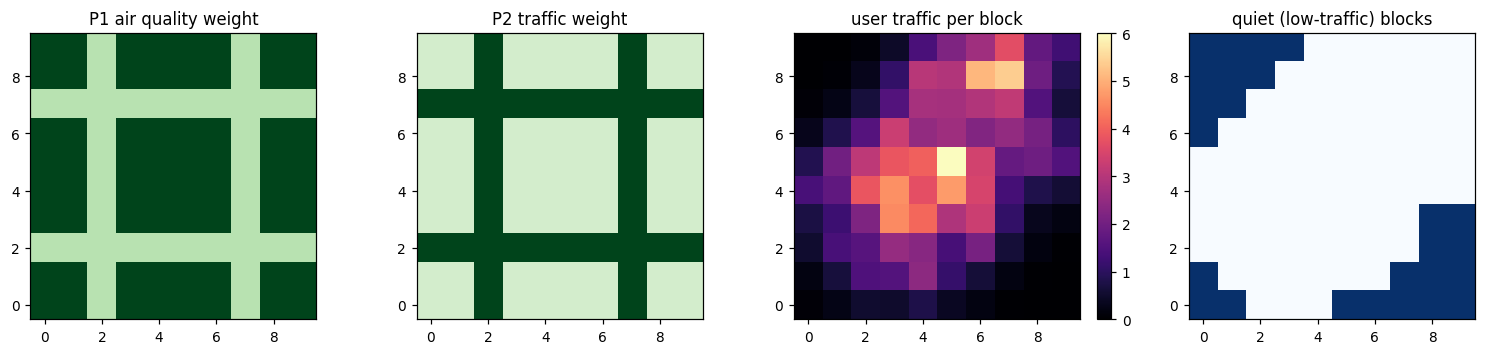

In [2]:
w = World(cfg)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for j, name in enumerate(["P1 air quality weight", "P2 traffic weight"]):
    im = ax[j].imshow(w.W[j].reshape(10, 10), origin="lower", cmap="Greens", vmin=0, vmax=1); ax[j].set_title(name)
im = ax[2].imshow(w.traffic.reshape(10, 10), origin="lower", cmap="magma"); ax[2].set_title("user traffic per block"); plt.colorbar(im, ax=ax[2], fraction=.046)
ax[3].imshow(w.low_traffic.reshape(10, 10), origin="lower", cmap="Blues"); ax[3].set_title("quiet (low-traffic) blocks")
plt.tight_layout(); plt.show()

## 0. Checks on the users' game (Proposition 1)
1. The potential identity $\Delta\Phi=\Delta u_i$ holds for random unilateral moves.
2. Best-response dynamics reach a pure NE, and $\Phi$ rises monotonically along the way.
3. Log-linear learning at low temperature finds higher-potential equilibria.
4. Brute force on small games: every instance has a pure NE, BR always finds one, and we compute PoA/PoS.

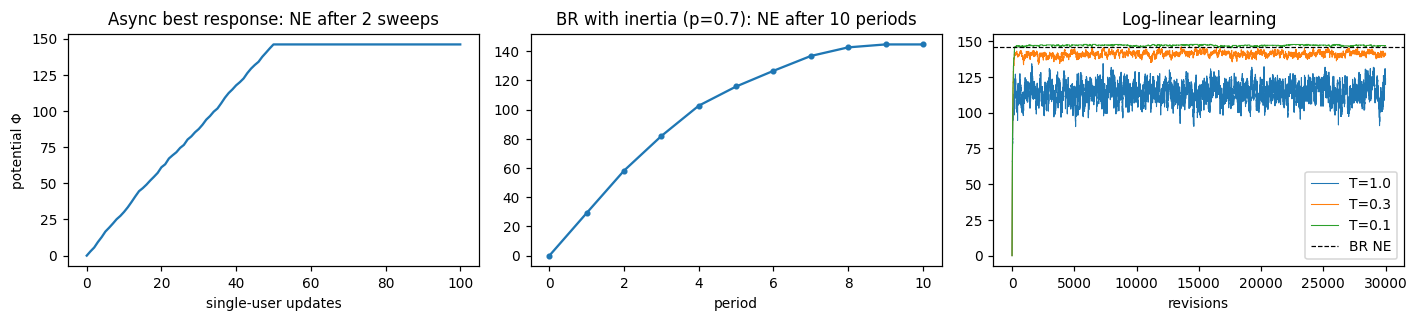

max |ΔΦ - Δu| over 5000 random deviations = 2.8e-14;  BR profile is NE: True;  inertia profile is NE: True
mean Φ under LLL (last 5000 steps): {1.0: 114.5, 0.3: 141.5, 0.1: 147.0}  BR NE Φ: 145.9


In [3]:
rng = np.random.default_rng(7)
acts = w.build_actions(w.draw_routes(rng)); R = w.W * cfg.b
g = UserGame(R, acts)
a_br, sweeps, tr_br = async_best_response(g, np.random.default_rng(1), record=True, check_potential=True)
err = 0.0
for _ in range(5000):
    i = rng.integers(g.N); b = a_br.copy(); b[i] = rng.integers(-1, len(acts[i][0]))
    err = max(err, abs((g.potential(b) - g.potential(a_br)) - (g.utility(i, b) - g.utility(i, a_br))))
a_in, steps, tr_in = br_with_inertia(g, np.random.default_rng(2), p_inertia=0.7)
lll = {T: log_linear(g, np.random.default_rng(3), T=T, steps=30000)[1] for T in (1.0, 0.3, 0.1)}
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].plot(tr_br); ax[0].set(title=f"Async best response: NE after {sweeps} sweeps", xlabel="single-user updates", ylabel="potential Φ")
ax[1].plot(tr_in, ".-"); ax[1].set(title=f"BR with inertia (p=0.7): NE after {steps} periods", xlabel="period")
for T, tr in lll.items(): ax[2].plot(tr, lw=.7, label=f"T={T}")
ax[2].axhline(tr_br[-1], c="k", ls="--", lw=.8, label="BR NE"); ax[2].legend(); ax[2].set(title="Log-linear learning", xlabel="revisions")
plt.tight_layout(); plt.show()
print(f"max |ΔΦ - Δu| over 5000 random deviations = {err:.1e};  BR profile is NE: {g.is_nash(a_br)};  inertia profile is NE: {g.is_nash(a_in)}")
print("mean Φ under LLL (last 5000 steps):", {T: round(float(np.mean(tr[-5000:])), 1) for T, tr in lll.items()}, " BR NE Φ:", round(tr_br[-1], 1))

In [4]:
rng = np.random.default_rng(11); rows = []
for s in range(300):
    W_, kappa, acts_, R_ = random_tiny_instance(rng)
    gg = UserGame(R_, acts_); ne, opt = brute_force(gg, W_, cfg.V, cfg.rho)
    a, _, _ = async_best_response(gg, np.random.default_rng(s))
    welf = [x[1] for x in ne]
    rows.append(dict(n_NE=len(ne), BR_finds_NE=gg.is_nash(a), PoA=opt / min(welf) if min(welf) > 0 else np.nan,
                     PoS=opt / max(welf) if max(welf) > 0 else np.nan))
bf = pd.DataFrame(rows)
print(f"300 random games (4 users, 3 blocks, 2 apps): every game has a pure NE: {(bf.n_NE >= 1).all()}, BR always reaches a NE: {bf.BR_finds_NE.all()}")
bf[["n_NE", "PoA", "PoS"]].describe().loc[["mean", "50%", "max"]]

300 random games (4 users, 3 blocks, 2 apps): every game has a pure NE: True, BR always reaches a NE: True


,n_NE,PoA,PoS
mean,6.05,1.221,1.075
50%,5.00,1.173,1.003
max,24.00,2.807,2.807


## 1. Experiment 1: baseline (fixed price $m=1$ for both apps)
We run 10 seeds × 500 hours. Each hour, users settle to a NE of the stage-2 game. No one learns.

**Benchmark:** a greedy welfare-maximizing assignment, i.e. what a central planner would roughly achieve.

,mean over seeds,sd
coverage,0.498,1.497e-04
low_traffic_coverage,0.062,1.840e-03
profit0,183.277,3.730e-01
profit1,65.820,3.772e-01
spend0,182.944,3.788e-01
spend1,65.816,3.769e-01
user_net_mean,2.880,1.453e-03
users0,36.655,7.461e-02
users1,13.164,7.544e-02
welfare_ratio,1.004,4.507e-04


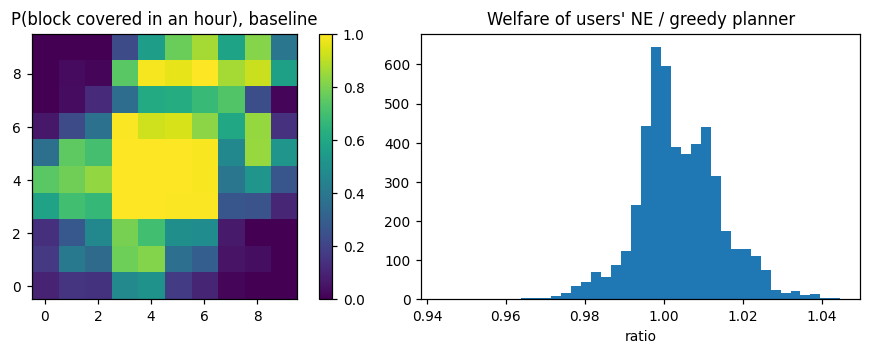

In [5]:
base_rows, covmaps = [], []
for s in SEEDS:
    mdl = CrowdsensingModel(cfg, [FixedPrice(1.0), FixedPrice(1.0)], seed=s)
    h = pd.DataFrame(mdl.run(500)); h["seed"] = s; base_rows.append(h); covmaps.append(mdl.cover_count / 500)
base = pd.concat(base_rows)
base["welfare_ratio"] = base.welfare / base.welfare_greedy
b_summary = base.groupby("seed")[["coverage", "low_traffic_coverage", "profit0", "profit1", "spend0", "spend1",
                                  "user_net_mean", "users0", "users1", "welfare_ratio"]].mean()
display(b_summary.agg(["mean", "std"]).T.rename(columns={"mean": "mean over seeds", "std": "sd"}))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
im = ax[0].imshow(np.mean(covmaps, 0).reshape(10, 10), origin="lower", vmin=0, vmax=1); plt.colorbar(im, ax=ax[0], fraction=.046)
ax[0].set_title("P(block covered in an hour), baseline")
ax[1].hist(base.welfare_ratio, bins=40); ax[1].set(title="Welfare of users' NE / greedy planner", xlabel="ratio")
plt.tight_layout(); plt.show()

## 2. Experiment 2: do learning apps drift to 'keep pay low'?

**Step 1: stage-game benchmarks.** For each price pair on $\mathcal M=\{0.4,\dots,1.6\}$, users' equilibrium outcomes are computed on a bank of 200 hourly route draws. From this we get the static Nash prices (competitive) and the joint-profit prices (collusive).

bank built in 6s
pure NE: none -> mixed equilibrium
  mixed NE  P1: {np.float64(0.8): np.float64(0.45), np.float64(1.0): np.float64(0.1), np.float64(1.2): np.float64(0.44)}  P2: {np.float64(1.0): np.float64(0.25), np.float64(1.2): np.float64(0.29), np.float64(1.4): np.float64(0.46)}
competitive (Nash):  mean price levels 1.00, 1.24;  joint profit Π^N = 212.5
collusive:           price levels 0.60, 0.60;  joint profit Π^C = 335.1


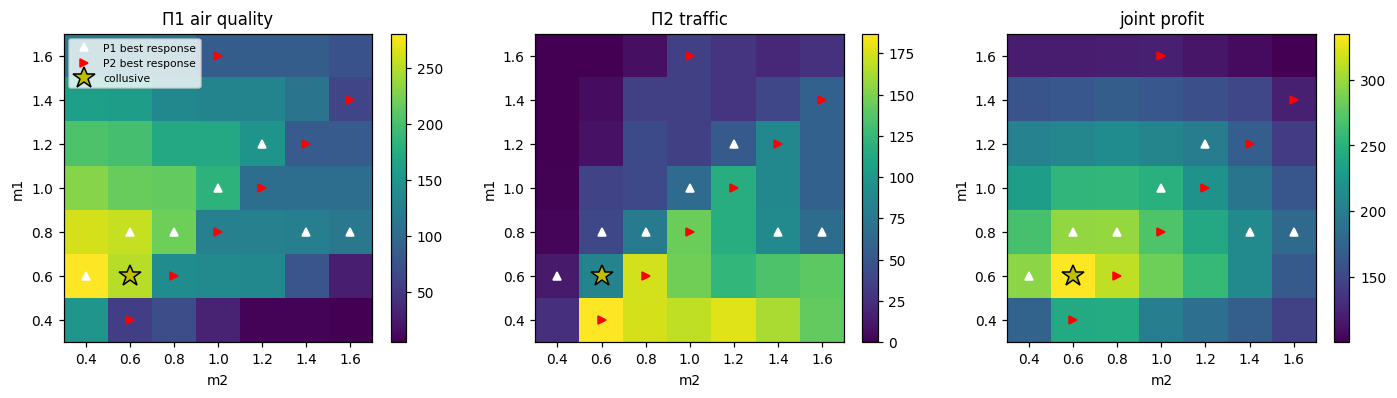

In [6]:
grid = np.round(np.arange(0.4, 1.61, 0.2), 2)
t = time.time(); bank = build_bank(cfg, grid, K=200); print(f"bank built in {time.time()-t:.0f}s")
bm = benchmarks(bank["Pi"]); Pi = bank["Pi"]; L = len(grid)
print("pure NE:", bm.get("all_pure", "none"), "->", bm["nash_type"], "equilibrium")
if bm["nash_type"] == "mixed":
    x, y = bm["nash"]
    print("  mixed NE  P1:", {grid[i]: round(p, 2) for i, p in enumerate(x) if p > 1e-6}, " P2:", {grid[i]: round(p, 2) for i, p in enumerate(y) if p > 1e-6})
    mN = (x @ grid, y @ grid)
else:
    mN = (grid[bm["nash"][0]], grid[bm["nash"][1]])
c = bm["collusive"]; mC = (grid[c[0]], grid[c[1]])
print(f"competitive (Nash):  mean price levels {mN[0]:.2f}, {mN[1]:.2f};  joint profit Π^N = {bm['pi_N']:.1f}")
print(f"collusive:           price levels {mC[0]:.2f}, {mC[1]:.2f};  joint profit Π^C = {bm['pi_C']:.1f}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (M_, ttl) in enumerate([(Pi[..., 0], "Π1 air quality"), (Pi[..., 1], "Π2 traffic"), (Pi.sum(-1), "joint profit")]):
    im = ax[k].imshow(M_, origin="lower"); plt.colorbar(im, ax=ax[k], fraction=.046)
    ax[k].set(xticks=range(L), yticks=range(L), xticklabels=grid, yticklabels=grid, xlabel="m2", ylabel="m1", title=ttl)
    ax[k].plot(range(L), Pi[..., 0].argmax(0), "w^", ms=5, label="P1 best response")
    ax[k].plot(Pi[..., 1].argmax(1), range(L), "r>", ms=5, label="P2 best response")
    ax[k].plot(c[1], c[0], "y*", ms=15, mec="k", label="collusive")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Step 2: Q-learning.** Two independent Q-learners run for 10 seeds each. Each run lasts until the learned strategies stop changing (up to $10^6$ hours, replaying the 200-hour bank).

**Controls:**
- *myopic* ($\gamma=0$): apps only care about today.
- *memoryless*: apps can't see last round's prices, so they can't reward or punish.

Calvano et al. find that both controls remove most of the collusion.

In [7]:
def delta(joint): return (joint - bm["pi_N"]) / (bm["pi_C"] - bm["pi_N"])
runs, qrows = {}, []
for label, kw in [("Q-learning", {}), ("control: myopic γ=0", {"gamma": 0.0}), ("control: memoryless", {"memory": False})]:
    for s in SEEDS:
        r = run_qlearning(bank, seed=s, **kw); lo = limit_outcome(r, bank); runs[(label, s)] = r
        qrows.append(dict(setting=label, seed=s, converged=r["converged"], rounds=r["t_end"], m1=lo["m_mean"][0], m2=lo["m_mean"][1],
                          profit1=lo["profit"][0], profit2=lo["profit"][1], joint=lo["joint"], Delta=delta(lo["joint"]),
                          coverage=lo["coverage"], low_cov=lo["low"], user_net=lo["usernet"], cycle_len=lo["cycle_len"]))
q = pd.DataFrame(qrows)
qsum = q.groupby("setting")[["converged", "rounds", "m1", "m2", "profit1", "profit2", "joint", "Delta", "coverage", "low_cov", "user_net"]].mean()
ref = pd.DataFrame({"m1": [mN[0], mC[0]], "m2": [mN[1], mC[1]], "joint": [bm["pi_N"], bm["pi_C"]], "Delta": [0, 1]},
                   index=["benchmark: static Nash", "benchmark: collusive"])
display(pd.concat([qsum, ref]))
display(q[q.setting == "Q-learning"][["seed", "rounds", "m1", "m2", "joint", "Delta", "cycle_len"]].set_index("seed").T)

,converged,rounds,m1,m2,profit1,profit2,joint,Delta,coverage,low_cov,user_net
Q-learning,1.0,634600.0,0.762,0.880,174.141,112.568,286.709,0.605,0.493,0.081,1.982
control: memoryless,1.0,800900.0,0.600,0.940,137.854,154.559,292.414,0.652,0.488,0.097,1.738
control: myopic γ=0,1.0,891700.0,0.800,1.200,129.459,112.114,241.573,0.237,0.498,0.096,2.901
benchmark: static Nash,NaN,NaN,0.998,1.242,NaN,NaN,212.530,0.000,NaN,NaN,NaN
benchmark: collusive,NaN,NaN,0.600,0.600,NaN,NaN,335.055,1.000,NaN,NaN,NaN


seed,0,1,2,3,4,5,6,7,8,9
rounds,618000.000,540000.000,664000.000,569000.000,796000.000,616000.000,749000.000,582000.000,688000.000,524000.000
m1,0.700,0.800,0.800,0.700,0.864,0.900,0.700,0.700,0.760,0.700
m2,0.800,0.900,0.900,0.900,1.000,1.000,0.800,0.800,1.000,0.700
joint,302.890,284.305,284.305,290.740,258.963,259.837,305.438,305.438,270.121,305.050
Delta,0.737,0.586,0.586,0.638,0.379,0.386,0.758,0.758,0.470,0.755
cycle_len,2.000,2.000,2.000,2.000,6.000,2.000,2.000,2.000,5.000,2.000


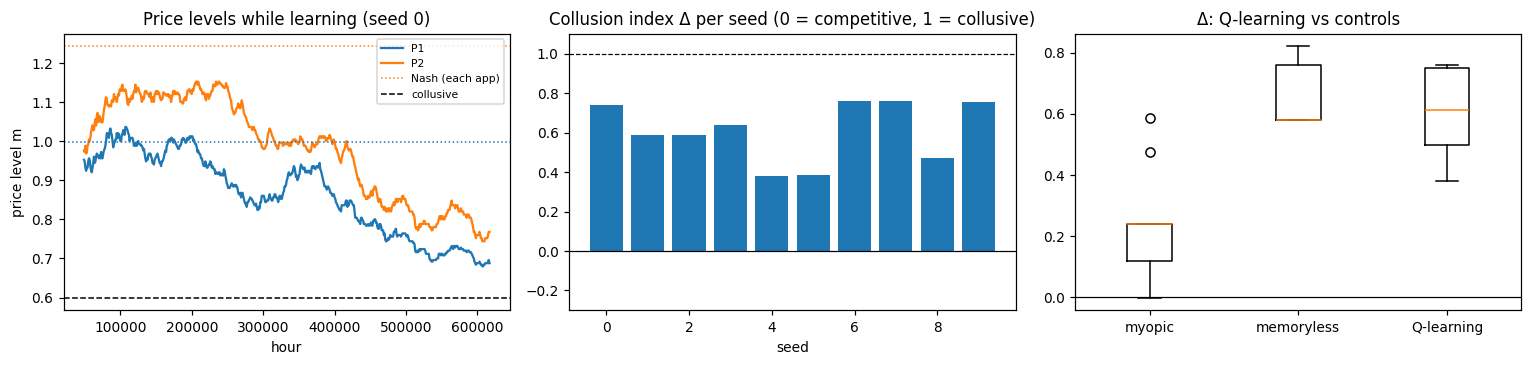

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
tr = runs[("Q-learning", 0)]["trace"]; win = 50
for j, lab in [(1, "P1"), (2, "P2")]:
    sm = np.convolve(grid[tr[:, j].astype(int)], np.ones(win) / win, mode="valid")
    ax[0].plot(tr[win - 1:, 0], sm, label=lab)
ax[0].axhline(mN[0], c="C0", ls=":", lw=1); ax[0].axhline(mN[1], c="C1", ls=":", lw=1, label="Nash (each app)")
ax[0].axhline(mC[0], c="k", ls="--", lw=1, label="collusive")
ax[0].set(title="Price levels while learning (seed 0)", xlabel="hour", ylabel="price level m"); ax[0].legend(fontsize=7)
qq = q[q.setting == "Q-learning"]
ax[1].bar(range(len(qq)), qq.Delta); ax[1].axhline(0, c="k", lw=.8); ax[1].axhline(1, c="k", ls="--", lw=.8)
ax[1].set(title="Collusion index Δ per seed (0 = competitive, 1 = collusive)", xlabel="seed", ylim=(-0.3, 1.1))
order = ["control: myopic γ=0", "control: memoryless", "Q-learning"]
ax[2].boxplot([q[q.setting == o].Delta for o in order], tick_labels=["myopic", "memoryless", "Q-learning"]); ax[2].axhline(0, c="k", lw=.8)
ax[2].set(title="Δ: Q-learning vs controls")
plt.tight_layout(); plt.show()

**Step 3: punishment test.** After learning, we force P1 (and separately P2) to deviate once to its one-shot most profitable price, the one that steals users from the rival. Then both apps follow their learned strategies again.

If the rival answers with a bounty war and both return to the old prices afterwards, the high-profit outcome is being *enforced*, not just stumbled into. We also check whether deviating paid off over the next 15 rounds.

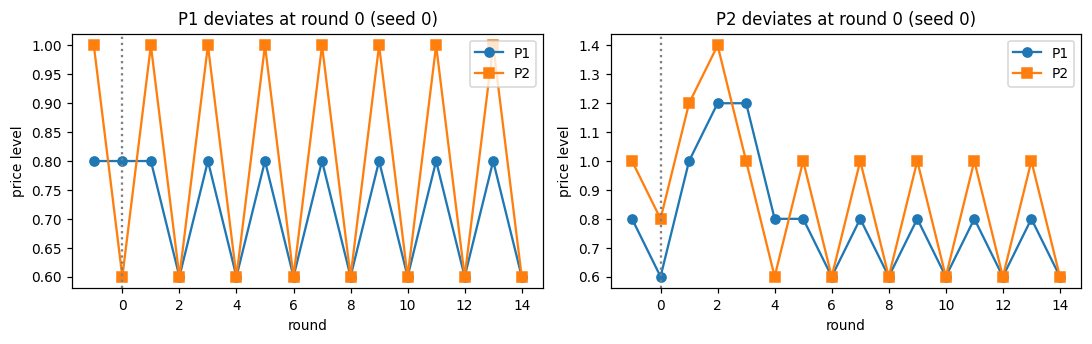

rival raises its bounty right after the deviation in 50% of cases


one_shot_gain              discounted_net_gain                
                  mean  min     max                mean     min     max
deviator                                                               
P1              41.669  0.0  81.015             -13.436 -83.942  60.794
P2              32.646  0.0  90.250             -15.296 -64.243  50.298

In [9]:
from crowdsim.learning import greedy_path
gains, punished = [], []
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for dvt in (0, 1):
    for s in SEEDS:
        r = runs[("Q-learning", s)]
        path = impulse_response(r, bank, deviator=dvt, horizon=15)
        # counterfactual: no deviation
        pre = greedy_path(r["Q"], L, r["last_state"], steps=120)
        s0 = pre[-1][0] * L + pre[-1][1]
        nodev = [pre[-1]] + greedy_path(r["Q"], L, s0, steps=15)
        idx = lambda m: (list(grid).index(round(m[0], 2)), list(grid).index(round(m[1], 2)))
        pd_ = [Pi[idx(m)][dvt] for m in path[1:]]; pn = [Pi[a][dvt] for a in nodev[1:]]
        disc = 0.95 ** np.arange(15)
        gains.append(dict(deviator=f"P{dvt+1}", seed=s, one_shot_gain=pd_[0] - pn[0], discounted_net_gain=float(disc @ (np.array(pd_) - np.array(pn)))))
        rival = 1 - dvt
        punished.append(path[2, rival] > path[0, rival])
        if s == 0:
            ax[dvt].plot(range(-1, 15), path[:, 0], "o-", label="P1"); ax[dvt].plot(range(-1, 15), path[:, 1], "s-", label="P2")
            ax[dvt].axvline(0, c="grey", ls=":"); ax[dvt].set(title=f"P{dvt+1} deviates at round 0 (seed 0)", xlabel="round", ylabel="price level"); ax[dvt].legend()
plt.tight_layout(); plt.show()
G = pd.DataFrame(gains)
print(f"rival raises its bounty right after the deviation in {np.mean(punished)*100:.0f}% of cases")
G.groupby("deviator")[["one_shot_gain", "discounted_net_gain"]].describe().loc[:, (slice(None), ["mean", "min", "max"])]

## 3. Experiment 3: users who lie about the rival's offer

Both apps use rival-offer learning (Section 5 of the formulation). We run 0%, 25% and 50% liars with $\delta=0.5$ (reporting 1.5× the true pay), for 10 seeds × 1500 hours.

The liar sets are nested: the 25% liars are also liars in the 50% run, so we can follow **the same people** across scenarios:
- **group A**: liars in both the 25% and 50% runs;
- **group B**: liars only in the 50% run;
- **group C**: never lie.

Outcomes are averaged over the last 1000 hours, after the transient.

In [10]:
T3, BURN = 1500, 500
def run3(share, seed, **kw):
    m = RivalOfferModel(cfg, liar_share=share, seed=seed, **kw)
    m.earn_tail = np.zeros(cfg.N)
    for t in range(T3):
        m.step()
        if t >= BURN: m.earn_tail += m.last_net
    m.earn_tail /= (T3 - BURN)
    return m
t = time.time(); M3 = {(sh, s): run3(sh, s) for sh in (0.0, 0.25, 0.5) for s in SEEDS}; print(f"{time.time()-t:.0f}s")
A = M3[(0.25, 0)].liar; AB = M3[(0.5, 0)].liar; B = AB & ~A; C = ~AB
rows = []
for (sh, s), m in M3.items():
    h = pd.DataFrame(m.hist).iloc[BURN:]
    rows.append(dict(liars=f"{int(sh*100)}%", seed=s, spend_P1=h.spend0.mean(), spend_P2=h.spend1.mean(),
                     profit_P1=h.profit0.mean(), profit_P2=h.profit1.mean(), coverage=h.coverage.mean(), low_cov=h.low.mean(),
                     earn_A=m.earn_tail[A].mean(), earn_B=m.earn_tail[B].mean(), earn_C=m.earn_tail[C].mean(), earn_all=m.earn_tail.mean()))
E3 = pd.DataFrame(rows)
tab = E3.groupby("liars").mean(numeric_only=True).drop(columns="seed")
display(tab.T)

67s


liars,0%,25%,50%
spend_P1,126.157,126.765,128.148
spend_P2,83.230,87.552,94.275
profit_P1,161.385,159.916,157.676
profit_P2,106.456,107.646,105.510
coverage,0.471,0.476,0.480
low_cov,0.306,0.305,0.305
earn_A,2.422,2.503,2.651
earn_B,1.906,1.985,2.137
earn_C,1.769,1.836,1.939
earn_all,1.961,2.035,2.161


change            change_pct         seeds_positive      
liars            25%        50%        25%     50%            25%   50%
metric                                                                 
coverage   4.336e-03  8.527e-03      0.920   1.809           10.0  10.0
earn_A     8.131e-02  2.288e-01      3.357   9.447           10.0  10.0
earn_B     7.896e-02  2.309e-01      4.145  12.118           10.0  10.0
earn_C     6.766e-02  1.706e-01      3.827   9.646           10.0  10.0
low_cov   -3.400e-04 -4.400e-04     -0.107  -0.139            4.0   4.0
profit_P1 -1.469e+00 -3.709e+00     -0.910  -2.298            0.0   0.0
profit_P2  1.189e+00 -9.466e-01      1.118  -0.889           10.0   0.0
spend_P1   6.086e-01  1.991e+00      0.483   1.578           10.0  10.0
spend_P2   4.322e+00  1.104e+01      5.194  13.271           10.0  10.0

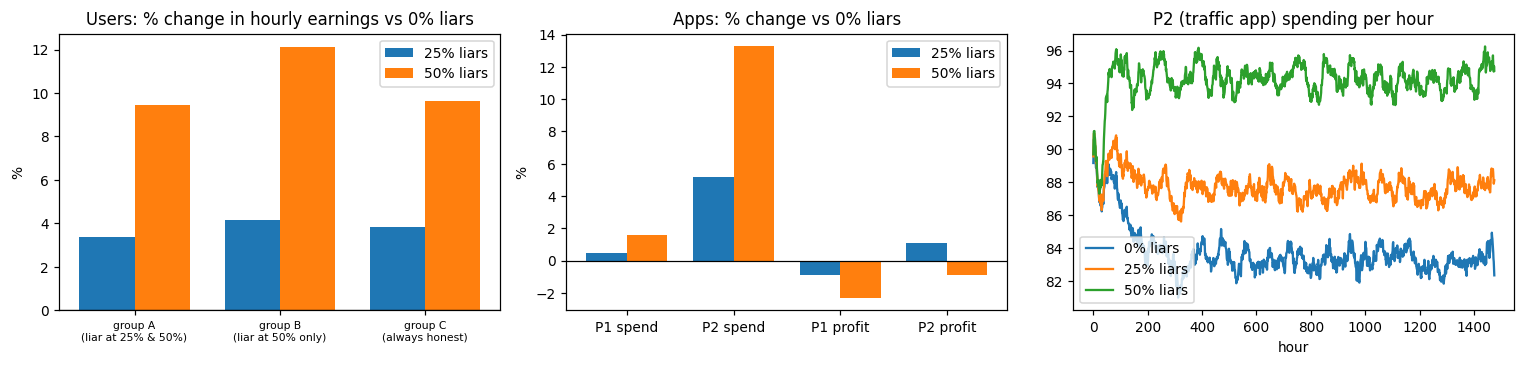

In [11]:
# paired changes vs the 0% world (same seed, same people), mean ± sd over seeds
base0 = E3[E3.liars == "0%"].set_index("seed")
chg = []
for lv in ("25%", "50%"):
    d = E3[E3.liars == lv].set_index("seed")[base0.columns.drop("liars")] - base0[base0.columns.drop("liars")]
    rel = 100 * d / base0[base0.columns.drop("liars")].abs()
    for col in ["spend_P1", "spend_P2", "profit_P1", "profit_P2", "earn_A", "earn_B", "earn_C", "coverage", "low_cov"]:
        chg.append(dict(liars=lv, metric=col, change=d[col].mean(), change_pct=rel[col].mean(), sd=d[col].std(),
                        seeds_positive=int((d[col] > 0).sum())))
CH = pd.DataFrame(chg).pivot(index="metric", columns="liars", values=["change", "change_pct", "seeds_positive"])
display(CH)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
lbl = {"earn_A": "group A\n(liar at 25% & 50%)", "earn_B": "group B\n(liar at 50% only)", "earn_C": "group C\n(always honest)"}
for k, lv in enumerate(("25%", "50%")):
    vals = [CH.loc[c, ("change_pct", lv)] for c in lbl]
    ax[0].bar(np.arange(3) + k * 0.38, vals, 0.38, label=f"{lv} liars")
ax[0].set_xticks(np.arange(3) + 0.19); ax[0].set_xticklabels(lbl.values(), fontsize=7); ax[0].axhline(0, c="k", lw=.8)
ax[0].set(title="Users: % change in hourly earnings vs 0% liars", ylabel="%"); ax[0].legend()
for k, lv in enumerate(("25%", "50%")):
    vals = [CH.loc[c, ("change_pct", lv)] for c in ["spend_P1", "spend_P2", "profit_P1", "profit_P2"]]
    ax[1].bar(np.arange(4) + k * 0.38, vals, 0.38, label=f"{lv} liars")
ax[1].set_xticks(np.arange(4) + 0.19); ax[1].set_xticklabels(["P1 spend", "P2 spend", "P1 profit", "P2 profit"]); ax[1].axhline(0, c="k", lw=.8)
ax[1].set(title="Apps: % change vs 0% liars", ylabel="%"); ax[1].legend()
for sh in (0.0, 0.25, 0.5):
    sp = np.mean([pd.DataFrame(M3[(sh, s)].hist).spend1.values for s in SEEDS], 0)
    ax[2].plot(np.convolve(sp, np.ones(25) / 25, mode="valid"), label=f"{int(sh*100)}% liars")
ax[2].set(title="P2 (traffic app) spending per hour", xlabel="hour"); ax[2].legend()
plt.tight_layout(); plt.show()

**Why do the two apps react differently?** Reports go only to the app a user *turned down*. Most users work for P1, so most reports land at P2, and P2's bounties are the ones that get pushed up.

**Sensitivity checks** (5 seeds each):
- a bigger lie, $\delta=1$ (report 2× the true pay);
- PACMAB's own update $\hat o\leftarrow\max(\hat o,r)$, under which a single inflated report raises the estimate permanently.

In [12]:
sens = []
for name, kw in [("δ=0.5, avg update", {}), ("δ=1.0, avg update", {"delta": 1.0}), ("δ=0.5, PACMAB max update", {"update": "max"})]:
    for sh in (0.0, 0.5):
        for s in range(5):
            m = run3(sh, s, **kw); h = pd.DataFrame(m.hist).iloc[BURN:]
            sens.append(dict(setting=name, liars=f"{int(sh*100)}%", seed=s, spend_P2=h.spend1.mean(), spend_total=h.spend0.mean() + h.spend1.mean(),
                             profit_total=h.profit0.mean() + h.profit1.mean(), earn_liars=m.earn_tail[AB].mean(), earn_honest=m.earn_tail[C].mean()))
S = pd.DataFrame(sens).groupby(["setting", "liars"]).mean(numeric_only=True).drop(columns="seed")
display(S)
print(f"total notebook runtime: {(time.time()-T0)/60:.1f} min")

spend_P2  spend_total  profit_total  \
setting                  liars                                        
δ=0.5, PACMAB max update 0%       83.119      209.191       268.121   
                         50%      98.246      227.051       260.606   
δ=0.5, avg update        0%       83.084      209.128       268.042   
                         50%      94.073      222.041       263.632   
δ=1.0, avg update        0%       83.084      209.128       268.042   
                         50%     102.602      231.113       256.967   

                                earn_liars  earn_honest  
setting                  liars                           
δ=0.5, PACMAB max update 0%          2.151        1.765  
                         50%         2.467        2.010  
δ=0.5, avg update        0%          2.151        1.762  
                         50%         2.377        1.930  
δ=1.0, avg update        0%          2.151        1.762  
                         50%         2.561        2.063

total notebook runtime: 4.6 min


## 4. Summary
The interpretation of these numbers is in `report.md`. Short version:
1. **Baseline:** about half the city is covered, but quiet areas almost never are.
2. **Learning prices:** Q-learning apps settle well above the competitive profit level, i.e. pay users less. The *controls* tell us whether this is genuine collusion: it is only collusion if strategies that can't reward or punish don't get there.
3. **Lying:** lying users push up the bounties of the app they turn down. The money goes to everyone on those blocks, so honest users free-ride; the app that receives the reports pays for it.